## **Expert Systems**

An **expert system** does not learn from data: its knowledge is a **knowledge base of rules written by specialists**, applied by an **inference engine** ( forward chaining ) that combines the evidence with **certainty factors**, as in MYCIN. This notebook keeps the original system and adds **a test of every rule ( ablation ), a check of the certainty factors against the data, a comparison between expert thresholds and data-driven thresholds, bootstrap intervals and reference models**.

**Notebooks of this series:** 1. CN2 Rule Induction · 2. Expert Systems · 3. Case-Based Reasoning · 4. Apriori for Classification ( CBA ) · 5. Simple Rule Learners ( ZeroR, OneR, PRISM ) · 6. RIPPER · 7. Rules from Decision Trees · 8. RuleFit · 9. Fuzzy Rule-Based Classifier

### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Rule-Based Techniques**

Models whose knowledge is a set of **IF ⟶ THEN** rules: transparent, auditable and easy to explain.

| Technique | Where the rules come from | Idea |
|---|---|---|
| **CN2** | learned from data | ordered rule list built by beam search (entropy + significance test) |
| **Expert system** | written by specialists | inference engine + knowledge base, with certainty factors |
| **Case-Based Reasoning** | no explicit rules: past **cases** | retrieve · reuse · revise · retain |
| **Apriori (CBA)** | mined from data | class association rules: frequent itemsets → class |

This notebook focuses on **Expert Systems**. All the techniques of the series are applied to the same problem: **malignant × benign** tumours ( Breast Cancer dataset ).

### **2. Dataset and Preparation**

* Positive class = **malignant** (1) · 10 *mean* attributes (readable rules)
* Train/test split **70/30**, stratified
* For CN2 and Apriori the attributes are **discretised** in 3 quantile bins (*low / mid / high*), fitted on the **training set only**

In [4]:
#Load the Breast Cancer Dataset ( Positive Class = Malignant )
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer(as_frame=True)
cols = [c for c in data.data.columns if c.startswith("mean ")]            # 10 "mean" attributes
X = data.data[cols]
y = (data.target == 0).astype(int)                                        # 1 = malignant, 0 = benign
CLASS_NAMES = ["benign", "malignant"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)
print("train:", X_train.shape, "| test:", X_test.shape, "| malignant in train:", f"{y_train.mean():.1%}")
X_train.head(3)

train: (398, 10) | test: (171, 10) | malignant in train: 37.2%


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension
78,20.18,23.97,143.70,1245.0,0.129,0.345,0.375,0.160,0.291,0.081
330,16.03,15.51,105.80,793.2,0.095,0.137,0.120,0.070,0.178,0.060
378,13.66,15.15,88.27,580.6,0.083,0.075,0.042,0.025,0.179,0.059


### **3. Expert Systems**

An expert system separates the **knowledge base** (rules written by specialists) from the **inference engine**.

* **Forward chaining:** facts → rules fire → new facts, until nothing changes
* **Certainty factors (MYCIN):** each rule carries a confidence $CF \in [-1, 1]$; evidence for the same conclusion is combined as $CF = CF_1 + CF_2 (1 - CF_1)$
* **Explanation facility:** the system can show **which rules fired** and why

> The thresholds below are **illustrative** (round values written *a priori*, not learned from the training set) and are **not** clinical advice.

In [11]:
#Knowledge Base and Inference Engine ( Forward Chaining with Certainty Factors )
class ExpertSystem:
    OPS = {">": lambda a, b: a > b, "<": lambda a, b: a < b}

    def __init__(self, rules):
        self.rules = rules                                       # list of dicts: name, if_, then, cf

    def infer(self, case, trace=False):
        facts = {}                                               # working memory: fact -> certainty factor
        log = []
        changed = True
        while changed:
            changed = False
            for r in self.rules:
                if r["name"] in [l["rule"] for l in log]:
                    continue
                ok = all((c[0] in case and self.OPS[c[1]](case[c[0]], c[2])) if c[0] in case else (c[0] in facts and facts[c[0]] > 0)
                         for c in r["if_"])
                if ok:
                    fact = r["then"]
                    old = facts.get(fact, 0.0)
                    facts[fact] = old + r["cf"] * (1 - old) if r["cf"] > 0 else old                    # combine positive evidence
                    log.append({"rule": r["name"], "concludes": fact, "cf": r["cf"]})
                    changed = True
        return (facts, log) if trace else facts

    def score(self, case):
        f = self.infer(case)
        pos, neg = f.get("malignant", 0.0), f.get("benign", 0.0)
        cf = (pos - neg) / (1 - min(abs(pos), abs(neg))) if min(abs(pos), abs(neg)) < 1 else 0.0         # MYCIN combination of opposite evidence
        return (cf + 1) / 2                                                                            # map [-1, 1] -> [0, 1]

knowledge_base = [
    # level 1: measurements -> symptoms (facts)
    {"name": "R1", "if_": [("mean radius", ">", 15)],                      "then": "large_nucleus",   "cf": 1.0},
    {"name": "R2", "if_": [("mean radius", "<", 12)],                      "then": "small_nucleus",   "cf": 1.0},
    {"name": "R3", "if_": [("mean concavity", ">", 0.10)],                 "then": "irregular_shape", "cf": 1.0},
    {"name": "R4", "if_": [("mean concave points", ">", 0.05)],            "then": "irregular_shape", "cf": 1.0},
    {"name": "R5", "if_": [("mean concavity", "<", 0.05)],                 "then": "regular_shape",   "cf": 1.0},
    {"name": "R6", "if_": [("mean area", ">", 800)],                       "then": "large_area",      "cf": 1.0},
    # level 2: symptoms -> diagnosis, with certainty factors
    {"name": "R7",  "if_": [("large_nucleus",), ("irregular_shape",)],     "then": "malignant", "cf": 0.80},
    {"name": "R8",  "if_": [("large_area",)],                              "then": "malignant", "cf": 0.50},
    {"name": "R9",  "if_": [("irregular_shape",)],                         "then": "malignant", "cf": 0.45},
    {"name": "R10", "if_": [("small_nucleus",), ("regular_shape",)],       "then": "benign",    "cf": 0.75},
    {"name": "R11", "if_": [("regular_shape",)],                           "then": "benign",    "cf": 0.40},
    {"name": "R12", "if_": [("small_nucleus",)],                           "then": "benign",    "cf": 0.30},
]
for r in knowledge_base:
    r["if_"] = [c if len(c) == 3 else (c[0], ">", 0) for c in r["if_"]]
es = ExpertSystem(knowledge_base)
print("knowledge base:", len(knowledge_base), "rules")

knowledge base: 12 rules


In [12]:
#Explanation Facility: Why Did the System Decide That? ( First Test Case with 4 or More Rules Fired )
for pos in range(len(X_test)):
    case = X_test.iloc[pos].to_dict()
    facts, log = es.infer(case, trace=True)
    if len(log) >= 4:
        break
print("case:", {k: round(v, 3) for k, v in case.items() if k in ("mean radius", "mean concavity", "mean concave points", "mean area")})
for step in log:
    print(f"  {step['rule']:>3} fired → {step['concludes']:<16} (CF = {step['cf']:.2f})")
print("accumulated certainty:", {k: round(v, 2) for k, v in facts.items() if k in ("malignant", "benign")})
print(f"score(malignant) = {es.score(case):.3f} | true class: {CLASS_NAMES[y_test.iloc[pos]]}")

case: {'mean radius': 7.76, 'mean area': 181.0, 'mean concavity': 0.0, 'mean concave points': 0.0}
   R2 fired → small_nucleus    (CF = 1.00)
   R5 fired → regular_shape    (CF = 1.00)
  R10 fired → benign           (CF = 0.75)
  R11 fired → benign           (CF = 0.40)
  R12 fired → benign           (CF = 0.30)
accumulated certainty: {'benign': 0.9}
score(malignant) = 0.052 | true class: benign


In [ ]:
#Dictionary Used to Collect the Test Metrics of This Notebook ( the Cells Below Add Their Results to It )
results = {}

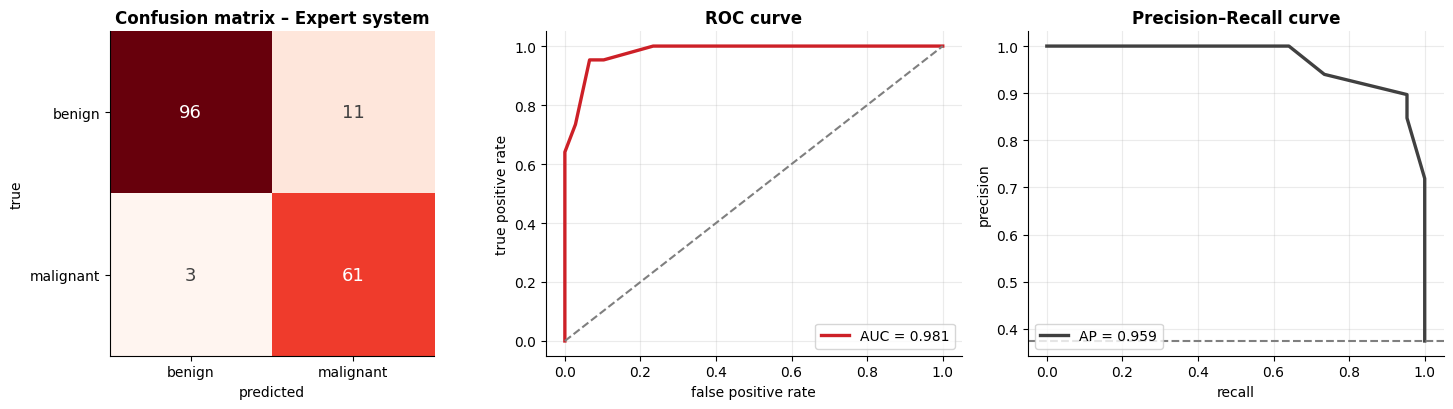

,accuracy,balanced acc.,precision,recall,F1,MCC,ROC AUC,PR AUC
Expert system,0.918,0.925,0.847,0.953,0.897,0.833,0.981,0.959


In [13]:
#Evaluate the Expert System on the Test Set
score_es = np.array([es.score(row) for row in X_test.to_dict("records")])
pred_es = (score_es > 0.5).astype(int)
results["Expert system"] = report_binary(y_test, pred_es, score_es, "Expert system", CLASS_NAMES)
results["Expert system"].to_frame().T

#### **Expert-System-Specific Metrics**

How often each rule **fires**, **coverage** (cases where at least one diagnosis rule fires), **conflicts** (evidence for both classes) and the distribution of the final score.

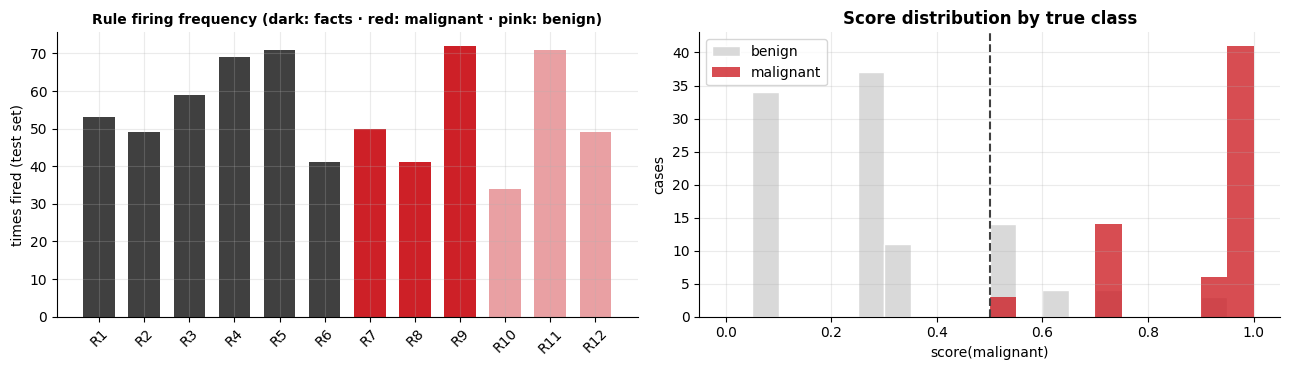

coverage: 90.1% of the cases have a diagnosis | conflicts (evidence for both classes): 2.3%


In [14]:
#Rule Firing Statistics, Coverage and Conflicts
fired = pd.Series(0, index=[r["name"] for r in knowledge_base])
conflict, covered = 0, 0
for row in X_test.to_dict("records"):
    f, log = es.infer(row, trace=True)
    for l in log: fired[l["rule"]] += 1
    covered += int(f.get("malignant", 0) > 0 or f.get("benign", 0) > 0)
    conflict += int(f.get("malignant", 0) > 0 and f.get("benign", 0) > 0)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(fired.index, fired.values, color=[DARK] * 6 + [RED] * 3 + [SOFT] * 3, width=0.7); axes[0].set_ylabel("times fired (test set)")
axes[0].set_title("Rule firing frequency (dark: facts · red: malignant · pink: benign)", fontsize=10); axes[0].tick_params(axis="x", rotation=45)
axes[1].hist(score_es[y_test == 0], bins=20, range=(0, 1), color=LIGHT, edgecolor="white", label="benign")
axes[1].hist(score_es[y_test == 1], bins=20, range=(0, 1), color=RED, alpha=0.8, label="malignant"); axes[1].axvline(0.5, color=DARK, ls="--")
axes[1].set_xlabel("score(malignant)"); axes[1].set_ylabel("cases"); axes[1].set_title("Score distribution by true class"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"coverage: {covered / len(X_test):.1%} of the cases have a diagnosis | conflicts (evidence for both classes): {conflict / len(X_test):.1%}")

### **4. Quality Metrics Beyond the Original Ones**

In [ ]:
#Ablation of the Knowledge Base: What Happens to the Test Metrics when One Rule Is Removed?
def evaluate_kb(rules, X, y):
    system = ExpertSystem(rules)
    score = np.array([system.score(row) for row in X.to_dict("records")])
    return accuracy_score(y, (score > 0.5).astype(int)), roc_auc_score(y, score)

base_acc, base_auc = evaluate_kb(knowledge_base, X_test, y_test)
rows = []
for r in knowledge_base:
    acc_i, auc_i = evaluate_kb([k for k in knowledge_base if k["name"] != r["name"]], X_test, y_test)
    rows.append({"rule removed": r["name"], "concludes": r["then"], "accuracy": acc_i, "change in accuracy": acc_i - base_acc, "ROC AUC": auc_i, "change in ROC AUC": auc_i - base_auc})
ablation = pd.DataFrame(rows)
print(f"complete knowledge base: accuracy {base_acc:.3f} | ROC AUC {base_auc:.3f}")
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(ablation["rule removed"], ablation["change in accuracy"], color=[RED if v < 0 else GRAY for v in ablation["change in accuracy"]], width=0.7)
ax.axhline(0, color=DARK, lw=1); ax.set_ylabel("change in test accuracy"); ax.set_title("Accuracy change when the rule is removed ( negative = the rule helps )")
plt.tight_layout(); plt.show()
ablation.round(3)

In [ ]:
#Are the Certainty Factors Consistent with the Data? Empirical Precision of Each Diagnosis Rule ( Training and Test Sets )
def firing_table(X, y):
    fired_cases = {r["name"]: [] for r in knowledge_base}
    for pos, row in enumerate(X.to_dict("records")):
        _, log = es.infer(row, trace=True)
        for l in log:
            fired_cases[l["rule"]].append(pos)
    out = {}
    for r in knowledge_base[6:]:
        pos = np.array(fired_cases[r["name"]], dtype=int)
        target = 1 if r["then"] == "malignant" else 0
        out[r["name"]] = (len(pos), (y.to_numpy()[pos] == target).mean() if len(pos) else np.nan)
    return out

train_fire, test_fire = firing_table(X_train, y_train), firing_table(X_test, y_test)
cf_check = pd.DataFrame([{"rule": r["name"], "concludes": r["then"], "certainty factor": r["cf"], "fires ( train )": train_fire[r["name"]][0], "precision ( train )": train_fire[r["name"]][1],
                          "fires ( test )": test_fire[r["name"]][0], "precision ( test )": test_fire[r["name"]][1]} for r in knowledge_base[6:]])
print("a certainty factor is a belief written by a person: the empirical precision shows which beliefs are too low or too high")
cf_check.round(3)

In [ ]:
#Expert Thresholds vs Thresholds Learned from the Training Data ( Same Rules, Same Certainty Factors )
def learned_cut(feature, high, target_precision=0.9, min_cases=20):
    x, yy = X_train[feature].to_numpy(), y_train.to_numpy()
    candidates = np.unique(x)
    best = None
    for t in candidates:
        m = (x > t) if high else (x < t)
        if m.sum() < min_cases:
            continue
        precision = (yy[m] == (1 if high else 0)).mean()
        if precision >= target_precision:
            if best is None or (high and t < best) or (not high and t > best):
                best = t
    return best

learned = {"R1": ("mean radius", ">", True), "R2": ("mean radius", "<", False), "R3": ("mean concavity", ">", True), "R4": ("mean concave points", ">", True),
           "R5": ("mean concavity", "<", False), "R6": ("mean area", ">", True)}
data_kb, rows = [dict(r) for r in knowledge_base], []
for r in data_kb[:6]:
    feature, op, high = learned[r["name"]]
    cut = learned_cut(feature, high)
    expert_cut = r["if_"][0][2]
    rows.append({"rule": r["name"], "condition": f"{feature} {op}", "expert threshold": expert_cut, "learned threshold ( precision ≥ 90% )": cut})
    if cut is not None:
        r["if_"] = [(feature, op, cut)]
acc_e, auc_e = evaluate_kb(knowledge_base, X_test, y_test)
acc_d, auc_d = evaluate_kb(data_kb, X_test, y_test)
print(f"expert thresholds: accuracy {acc_e:.3f}, ROC AUC {auc_e:.3f} | thresholds learned on the training set: accuracy {acc_d:.3f}, ROC AUC {auc_d:.3f}")
pd.DataFrame(rows).round(3)

In [ ]:
#Uncertainty of the Test Metrics ( Bootstrap of the Test Cases, 1,000 Resamples )
def bootstrap_ci(y_true, pred, score, n_boot=1000, seed=RANDOM_STATE):
    rng_b = np.random.default_rng(seed)
    y_true, pred, score = np.asarray(y_true), np.asarray(pred), np.asarray(score)
    acc, auc = [], []
    for _ in range(n_boot):
        i = rng_b.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[i])) < 2:
            continue
        acc.append((pred[i] == y_true[i]).mean())
        auc.append(roc_auc_score(y_true[i], score[i]))
    return pd.DataFrame({"accuracy": np.percentile(acc, [2.5, 50, 97.5]), "ROC AUC": np.percentile(auc, [2.5, 50, 97.5])}, index=["2.5%", "median", "97.5%"]).T

print("the test set has", len(y_test), "cases: differences smaller than these intervals are not reliable")
bootstrap_ci(y_test, pred_es, score_es).round(3)

In [ ]:
#Calibration of the Predicted Probabilities ( Brier Score and Reliability Curve )
from sklearn.metrics import brier_score_loss
from sklearn.calibration import calibration_curve

score_es_ARRAY = np.asarray(score_es, dtype=float)
frac_pos, mean_pred = calibration_curve(y_test, score_es_ARRAY, n_bins=5, strategy="quantile")                       # bins with the same number of cases
print(f"Brier score: {brier_score_loss(y_test, score_es_ARRAY):.4f} | Brier score of a model that always predicts the training prevalence: {brier_score_loss(y_test, np.full(len(y_test), y_train.mean())):.4f} ( lower is better )")
fig, ax = plt.subplots(figsize=(4.6, 4.2))
ax.plot([0, 1], [0, 1], color=GRAY, ls="--", label="perfect calibration"); ax.plot(mean_pred, frac_pos, color=RED, marker="o", label="Expert system")
ax.set_xlabel("mean predicted probability ( 5 bins of equal size )"); ax.set_ylabel("observed share of malignant"); ax.set_title("Reliability curve"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
#Reference Models on the Same Split ( Is the Technique Better than a Trivial or a Standard Model? )
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

references = {"Majority class": DummyClassifier(strategy="prior"),
              "Decision tree ( depth 3 )": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
              "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))}
reference_rows = {}
for ref_name, model in references.items():
    model.fit(X_train, y_train)
    reference_rows[ref_name] = report_binary(y_test, model.predict(X_test), model.predict_proba(X_test)[:, 1], ref_name, CLASS_NAMES, plot=False)
metric_cols = ["accuracy", "precision", "recall", "F1", "ROC AUC", "PR AUC"]
pd.concat([pd.DataFrame(results).T[metric_cols], pd.DataFrame(reference_rows).T[metric_cols]]).round(3)

### **5. Takeaways**

* **The rules are hypotheses:** the ablation shows which ones really help on data and which ones are neutral or harmful
* **Certainty factors are beliefs:** compare them with the empirical precision of the rules before trusting the numbers ( section 4 ); the score of the system is not a calibrated probability
* **Expert vs learned thresholds:** a few cut points learned from data can be compared with the written ones, but the knowledge base remains readable and auditable; the expert system needs **no training data**, only an expert
* The thresholds of the original knowledge base were written *a priori* ( not clinical advice ) and the test set is small: look at the bootstrap intervals before concluding that one version is better